In [ ]:
# Resolve the repository root so data/ and output/ paths work from any working directory
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "data").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Start

# Growth and Rank Concordance

Two descriptive checks requested by the supervisor. First, whether provinces
that grew faster in NTL per capita also grew faster in GDP per capita over the
overlap window. Second, how closely the ranking of provinces by GDP per capita
matches their ranking by NTL per capita.

In [1]:
# ============================================================
# Imports and plot settings
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_style("whitegrid")

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)

# Reading the Data

In [2]:
# ============================================================
# Read Data
# ============================================================

df_master = pd.read_excel(
    str(ROOT / "data/Validation/hies_ntl_gdp_master.xlsx")
)

print(df_master.shape)
print(df_master.columns.tolist())
print(df_master[['Year', 'GDP_per_Capita', 'NTL_Per_Capita']].isnull().sum())

(434, 19)
['Province_EN', 'Year', 'avg_exp_per_capita', 'real_exp_per_capita', 'Annual_Sum', 'Annual_Mean', 'NTL_Per_Capita', 'Population', 'GDP', 'GDP_per_Capita', 'log_Annual_Sum', 'log_Annual_Mean', 'log_NTL_Per_Capita', 'log_avg_exp_per_capita', 'log_real_exp_per_capita', 'log_GDP', 'log_GDP_per_Capita', 'GDP_score', 'NTL_score']
Year               0
GDP_per_Capita    93
NTL_Per_Capita    31
dtype: int64


In [3]:
# ============================================================
# Coverage check: which variables are observed in which years
# ============================================================

coverage = df_master.groupby('Year')[
    ['GDP_per_Capita', 'NTL_Per_Capita', 'real_exp_per_capita']
].count()

print(coverage.to_string())
print(f"\nProvinces: {df_master['Province_EN'].nunique()}")

      GDP_per_Capita  NTL_Per_Capita  real_exp_per_capita
Year                                                     
1390              31               0                   31
1391              31              31                   31
1392              31              31                   31
1393              31              31                   31
1394              31              31                   31
1395              31              31                   31
1396              31              31                   31
1397              31              31                   31
1398              31              31                   31
1399              31              31                   31
1400              31              31                   31
1401               0              31                   31
1402               0              31                   31
1403               0              31                   31

Provinces: 31


In [4]:
# ============================================================
# Overlap sample: years where both GDP and NTL are observed
# ============================================================

overlap_min, overlap_max = 1391, 1400

df_overlap = df_master[
    df_master['Year'].between(overlap_min, overlap_max)
].dropna(subset=['log_GDP_per_Capita', 'log_NTL_Per_Capita']).copy()

print(f"Overlap window: {overlap_min}-{overlap_max}")
print(f"Observations: {len(df_overlap)} | Provinces: {df_overlap['Province_EN'].nunique()}")

Overlap window: 1391-1400
Observations: 310 | Provinces: 31


In [5]:
# ============================================================
# Annualised log growth per province
# ============================================================

growth_rows = []

for province, group in df_overlap.groupby('Province_EN'):
    group = group.sort_values('Year')
    span = group['Year'].iloc[-1] - group['Year'].iloc[0]
    growth_rows.append({
        'Province_EN': province,
        'g_gdp': (group['log_GDP_per_Capita'].iloc[-1]
                  - group['log_GDP_per_Capita'].iloc[0]) / span * 100,
        'g_ntl': (group['log_NTL_Per_Capita'].iloc[-1]
                  - group['log_NTL_Per_Capita'].iloc[0]) / span * 100,
    })

df_growth = pd.DataFrame(growth_rows)
print(df_growth[['g_gdp', 'g_ntl']].describe().round(2).to_string())

       g_gdp  g_ntl
count  31.00  31.00
mean    0.90   5.72
std     1.82   2.14
min    -3.18  -0.83
25%     0.07   4.78
50%     0.57   5.67
75%     1.65   7.21
max     7.27   9.88


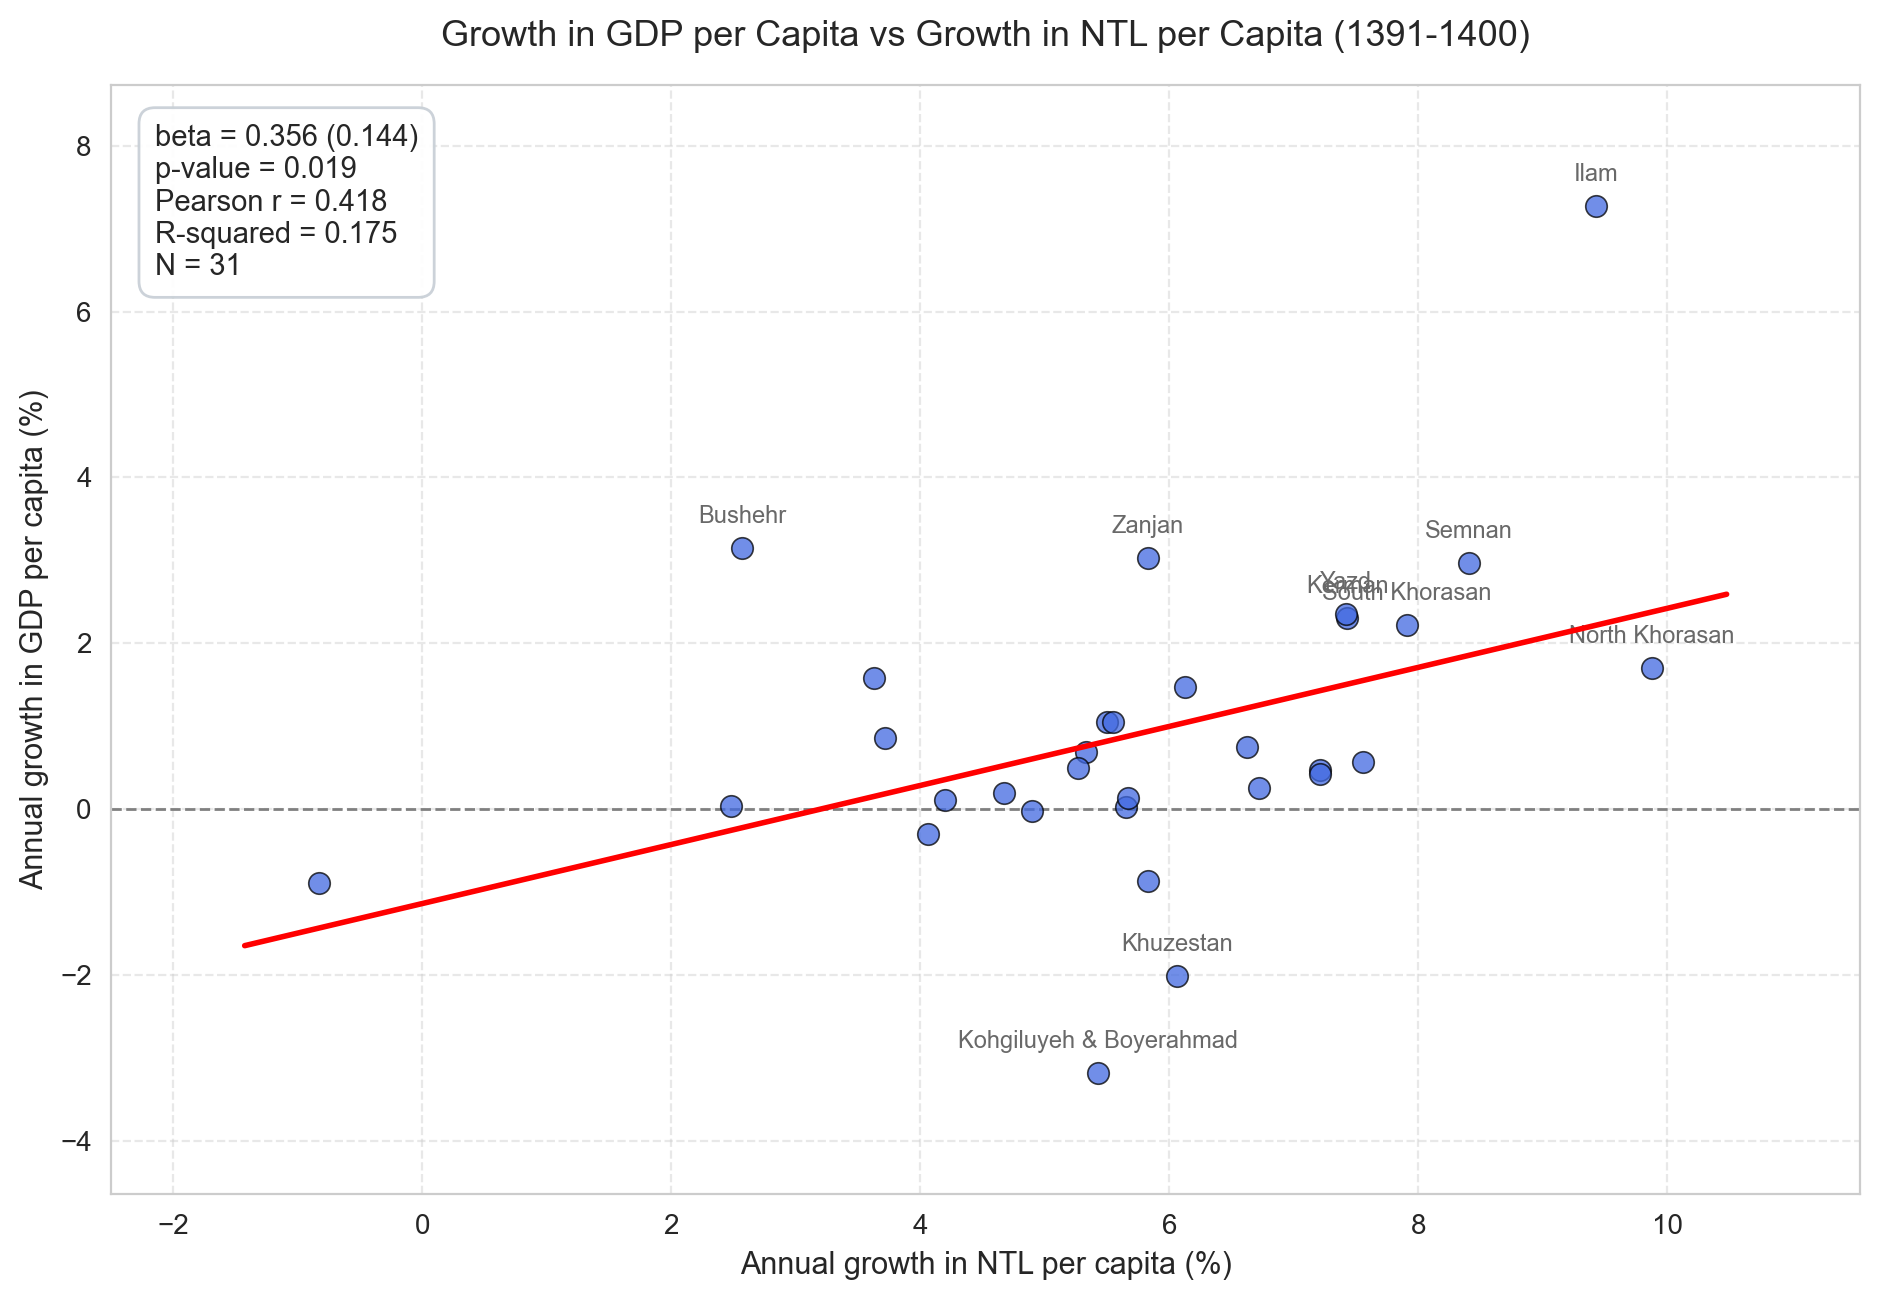

In [14]:
# ============================================================
# Scatter: growth in GDP per capita vs growth in NTL per capita
# ============================================================

LABEL_THRESHOLD = 1.6   # label a province if |GDP growth| exceeds this

r_g, _ = pearsonr(df_growth['g_ntl'], df_growth['g_gdp'])
model_growth = sm.OLS(df_growth['g_gdp'],
                      sm.add_constant(df_growth['g_ntl'])).fit()
beta_g = model_growth.params['g_ntl']
se_g   = model_growth.bse['g_ntl']

fig, ax = plt.subplots(figsize=(9.5, 6.6), dpi=200)

ax.axhline(0, linestyle='--', color='gray', linewidth=1, zorder=1)
ax.scatter(df_growth['g_ntl'], df_growth['g_gdp'],
           s=60, alpha=0.75, edgecolors='k', linewidths=0.6,
           color='royalblue', zorder=3)

xg = np.linspace(df_growth['g_ntl'].min() - 0.6,
                 df_growth['g_ntl'].max() + 0.6, 100)
ax.plot(xg, model_growth.params['const'] + beta_g * xg,
        color='red', linewidth=2, zorder=4)

# province labels
to_label = df_growth[df_growth['g_gdp'].abs() > LABEL_THRESHOLD]
try:
    from adjustText import adjust_text
    texts = [ax.text(r['g_ntl'], r['g_gdp'], r['Province_EN'],
                     fontsize=8.5, color='dimgray')
             for _, r in to_label.iterrows()]
    adjust_text(texts, ax=ax,
                arrowprops=dict(arrowstyle='-', color='silver', lw=0.6),
                expand=(1.2, 1.5), force_text=(0.4, 0.7))
except ImportError:
    for _, r in to_label.iterrows():
        ax.annotate(r['Province_EN'], (r['g_ntl'], r['g_gdp']),
                    textcoords='offset points', xytext=(0, 9),
                    ha='center', fontsize=8.5, color='dimgray')

ax.text(0.025, 0.965,
        f'beta = {beta_g:.3f} ({se_g:.3f})\n'
        f'p-value = {model_growth.pvalues["g_ntl"]:.3f}\n'
        f'Pearson r = {r_g:.3f}\n'
        f'R-squared = {model_growth.rsquared:.3f}\n'
        f'N = {len(df_growth)}',
        transform=ax.transAxes, fontsize=10.5, va='top', ha='left',
        bbox=dict(boxstyle='round,pad=0.55', facecolor='white',
                  edgecolor='#c8cfd6', alpha=0.93))

ax.set_title('Growth in GDP per Capita vs Growth in NTL per Capita '
             f'({overlap_min}-{overlap_max})', fontsize=13, pad=14)
ax.set_xlabel('Annual growth in NTL per capita (%)', fontsize=11)
ax.set_ylabel('Annual growth in GDP per capita (%)', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.45)
ax.margins(x=0.09, y=0.14)

plt.tight_layout()
plt.show()

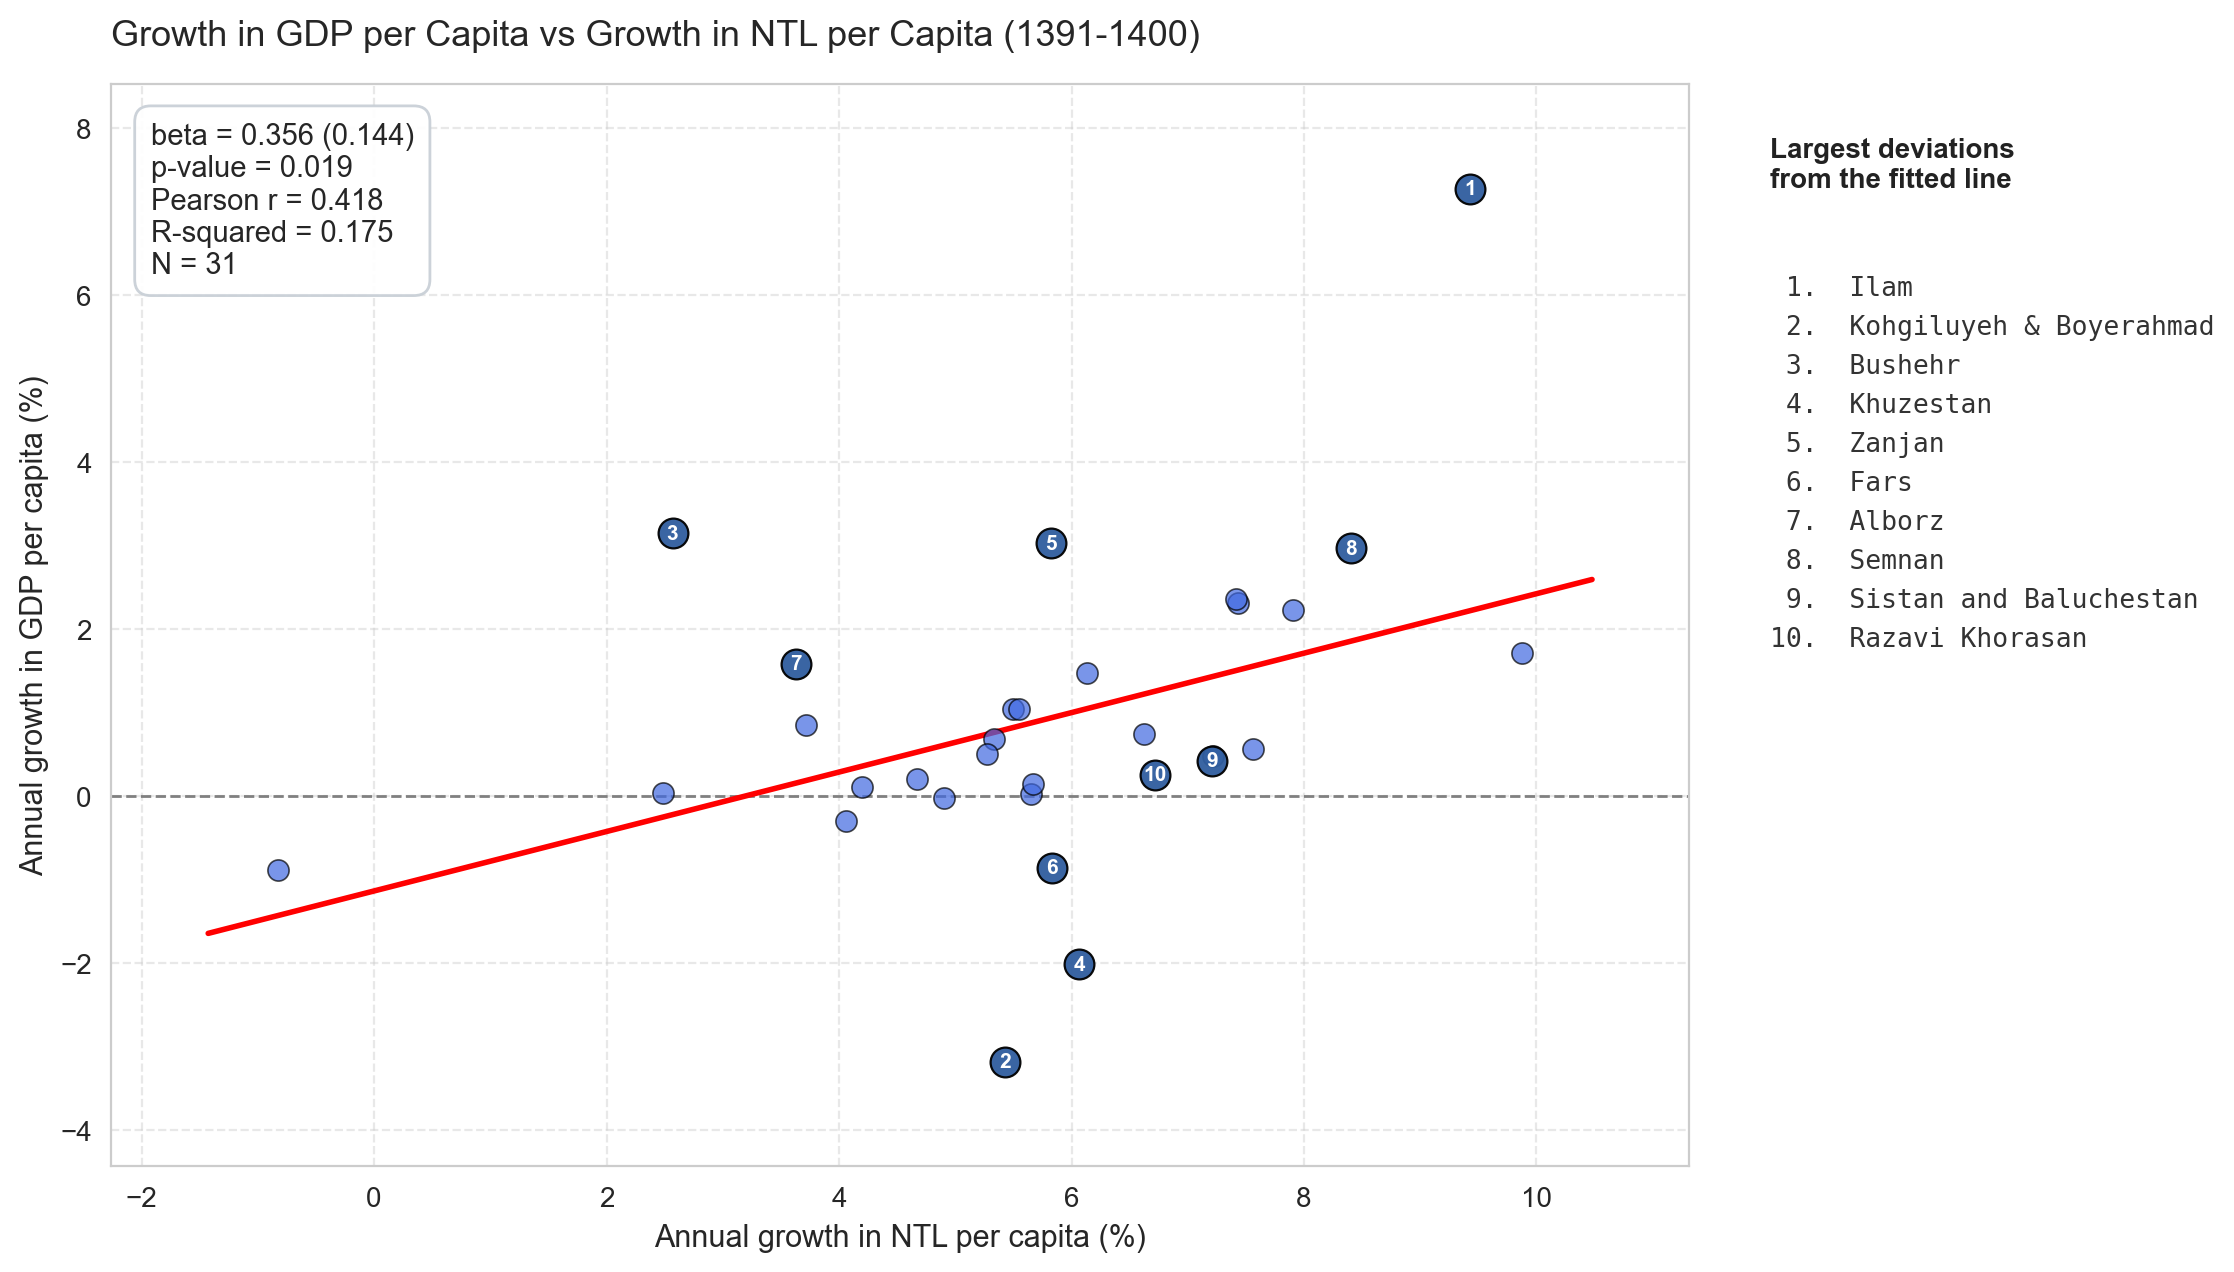

In [16]:
# ============================================================
# Scatter: growth in GDP per capita vs growth in NTL per capita
# Provinces furthest from the fitted line are numbered; key on the right
# ============================================================

N_LABEL = 10   # how many provinces to number

r_g, _ = pearsonr(df_growth['g_ntl'], df_growth['g_gdp'])
model_growth = sm.OLS(df_growth['g_gdp'],
                      sm.add_constant(df_growth['g_ntl'])).fit()
beta_g = model_growth.params['g_ntl']
se_g   = model_growth.bse['g_ntl']

# pick the provinces with the largest absolute residual
resid = (df_growth['g_gdp']
         - (model_growth.params['const'] + beta_g * df_growth['g_ntl'])).abs()
key = df_growth.loc[resid.nlargest(N_LABEL).index].copy()
key['num'] = range(1, len(key) + 1)

fig, ax = plt.subplots(figsize=(11.6, 6.6), dpi=200)

ax.axhline(0, linestyle='--', color='gray', linewidth=1, zorder=1)

xg = np.linspace(df_growth['g_ntl'].min() - 0.6,
                 df_growth['g_ntl'].max() + 0.6, 100)
ax.plot(xg, model_growth.params['const'] + beta_g * xg,
        color='red', linewidth=2, zorder=2)

other = df_growth.drop(key.index)
ax.scatter(other['g_ntl'], other['g_gdp'], s=58, alpha=0.70,
           edgecolors='k', linewidths=0.6, color='royalblue', zorder=3)
ax.scatter(key['g_ntl'], key['g_gdp'], s=115, alpha=0.95,
           edgecolors='k', linewidths=0.8, color='#2f5d9e', zorder=4)

for _, r in key.iterrows():
    ax.text(r['g_ntl'], r['g_gdp'], str(int(r['num'])),
            ha='center', va='center', fontsize=7.5,
            color='white', fontweight='bold', zorder=5)

ax.text(0.025, 0.965,
        f'beta = {beta_g:.3f} ({se_g:.3f})\n'
        f'p-value = {model_growth.pvalues["g_ntl"]:.3f}\n'
        f'Pearson r = {r_g:.3f}\n'
        f'R-squared = {model_growth.rsquared:.3f}\n'
        f'N = {len(df_growth)}',
        transform=ax.transAxes, fontsize=10.5, va='top', ha='left',
        bbox=dict(boxstyle='round,pad=0.55', facecolor='white',
                  edgecolor='#c8cfd6', alpha=0.93))

# key panel on the right
key_lines = [f"{int(r['num']):>2}.  {r['Province_EN']}" for _, r in key.iterrows()]
fig.text(0.785, 0.88, "Largest deviations\nfrom the fitted line",
         fontsize=10, fontweight='bold', va='top', ha='left', color='#222')
fig.text(0.785, 0.775, "\n".join(key_lines), fontsize=9.5, va='top', ha='left',
         family='DejaVu Sans Mono', color='#333', linespacing=1.65)

ax.set_title('Growth in GDP per Capita vs Growth in NTL per Capita '
             f'({overlap_min}-{overlap_max})', fontsize=13, pad=14, loc='left')
ax.set_xlabel('Annual growth in NTL per capita (%)', fontsize=11)
ax.set_ylabel('Annual growth in GDP per capita (%)', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.45)
ax.margins(x=0.07, y=0.12)

plt.subplots_adjust(left=0.07, right=0.75, top=0.92, bottom=0.10)
plt.show()

In [7]:
# ============================================================
# Rank concordance: Spearman by year
# ============================================================

spearman_rows = []

for year, group in df_overlap.groupby('Year'):
    rho, pval = spearmanr(group['GDP_per_Capita'], group['NTL_Per_Capita'])
    spearman_rows.append({'Year': year, 'N': len(group),
                          'spearman_rho': rho, 'p_value': pval})

df_spearman = pd.DataFrame(spearman_rows)
print(df_spearman.round(3).to_string(index=False))

 Year  N  spearman_rho  p_value
 1391 31         0.531    0.002
 1392 31         0.570    0.001
 1393 31         0.605    0.000
 1394 31         0.611    0.000
 1395 31         0.671    0.000
 1396 31         0.551    0.001
 1397 31         0.563    0.001
 1398 31         0.569    0.001
 1399 31         0.518    0.003
 1400 31         0.537    0.002


In [8]:
# ============================================================
# Ranks in the benchmark year
# ============================================================

benchmark_year = 1400

df_rank = df_overlap[df_overlap['Year'] == benchmark_year].copy()
df_rank['rank_gdp'] = df_rank['GDP_per_Capita'].rank(ascending=False).astype(int)
df_rank['rank_ntl'] = df_rank['NTL_Per_Capita'].rank(ascending=False).astype(int)
df_rank['rank_gap'] = (df_rank['rank_gdp'] - df_rank['rank_ntl']).abs()
df_rank = df_rank.sort_values('rank_gdp')

print(df_rank[['Province_EN', 'rank_gdp', 'rank_ntl', 'rank_gap']].to_string(index=False))
print(f"\nMean absolute rank gap: {df_rank['rank_gap'].mean():.2f}")
print(f"Largest discrepancies:")
print(df_rank.nlargest(6, 'rank_gap')[['Province_EN', 'rank_gdp', 'rank_ntl', 'rank_gap']].to_string(index=False))

              Province_EN  rank_gdp  rank_ntl  rank_gap
                  Bushehr         1         2         1
                Khuzestan         2         4         2
  Kohgiluyeh & Boyerahmad         3         3         0
                     Ilam         4         1         3
                     Yazd         5         6         1
                   Tehran         6        31        25
                   Semnan         7         5         2
                  Markazi         8        12         4
                Hormozgan         9         8         1
                   Zanjan        10        15         5
                  Isfahan        11        14         3
                   Kerman        12         9         3
                   Qazvin        13        16         3
               Mazandaran        14        24        10
          East Azerbaijan        15        21         6
                     Fars        16        11         5
                   Alborz        17        26   

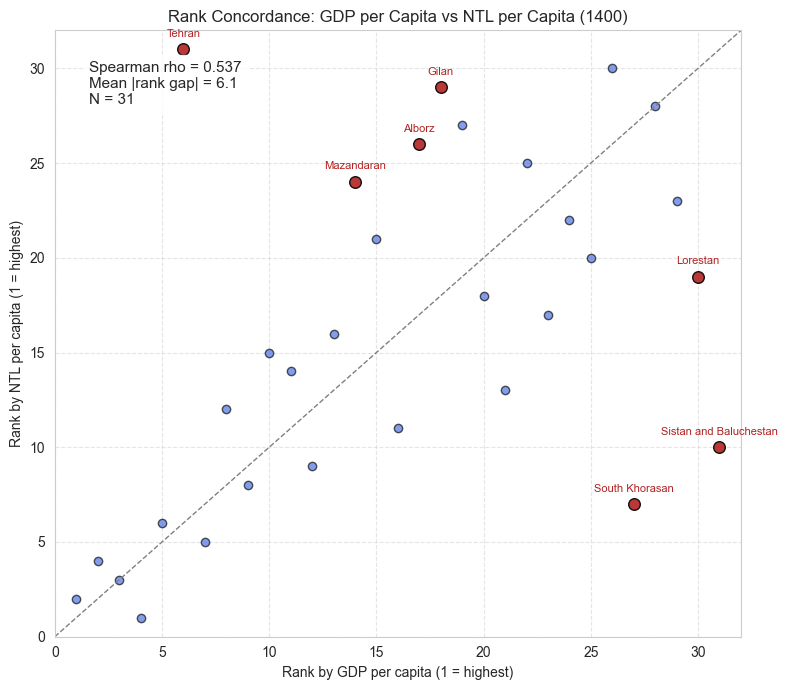

In [9]:
# ============================================================
# Scatter: rank by GDP per capita vs rank by NTL per capita
# ============================================================

rho_bm, _ = spearmanr(df_rank['GDP_per_Capita'], df_rank['NTL_Per_Capita'])
n_prov = len(df_rank)
gap_cut = 9

plt.figure(figsize=(8, 7))
plt.plot([0, n_prov + 1], [0, n_prov + 1], linestyle='--', color='gray', linewidth=1)

small = df_rank['rank_gap'] < gap_cut
plt.scatter(df_rank.loc[small, 'rank_gdp'], df_rank.loc[small, 'rank_ntl'],
            alpha=0.65, edgecolors='k', color='royalblue')
plt.scatter(df_rank.loc[~small, 'rank_gdp'], df_rank.loc[~small, 'rank_ntl'],
            alpha=0.9, edgecolors='k', color='firebrick', s=70)

for _, row in df_rank[~small].iterrows():
    plt.annotate(row['Province_EN'], (row['rank_gdp'], row['rank_ntl']),
                 textcoords='offset points', xytext=(0, 9),
                 ha='center', fontsize=8, color='firebrick')

plt.text(0.05, 0.95,
         f"Spearman rho = {rho_bm:.3f}\n"
         f"Mean |rank gap| = {df_rank['rank_gap'].mean():.1f}\nN = {n_prov}",
         transform=plt.gca().transAxes, fontsize=11,
         verticalalignment='top', bbox=dict(facecolor='white', alpha=0.8))

plt.xlim(0, n_prov + 1)
plt.ylim(0, n_prov + 1)
plt.title(f'Rank Concordance: GDP per Capita vs NTL per Capita ({benchmark_year})')
plt.xlabel('Rank by GDP per capita (1 = highest)')
plt.ylabel('Rank by NTL per capita (1 = highest)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()